# MetroMart–HSIC: the story in numbers
A walk-through of slides 4–7. All logic lives in `analysis/`; this notebook only imports it and reads `outputs/key_numbers.json`, so run `python analysis/run_all.py` first.

In [1]:
import json, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, display
from analysis import config as C, experiments_f as F, experiments_h as H
n = {k: v['value'] for k, v in json.loads((C.OUTPUTS / 'key_numbers.json').read_text(encoding='utf-8')).items()}
show = lambda *keys: pd.Series({k: n[k] for k in keys}, dtype=object)
chart = lambda name: display(Image(str(C.CHARTS / f'{name}.png'), width=900))

## Slide 4: the decline
SoW fell from 28.9% to 19.5%. Spend per card stayed flat while HSIC spend per card halved, and the Bridge puts the whole decline on cards that stayed open.

In [2]:
show('f1_sow_fy25', 'f1_sow_fy26', 'f1_sow_fy25_q1', 'f1_sow_fy26_q4', 'f1_slope_pp_per_quarter',
     'f14_aug24_net_per_card', 'f14_may26_net_per_card', 'f14_aug24_hsic_per_card', 'f14_may26_hsic_per_card')

f1_sow_fy25                   0.289095
f1_sow_fy26                   0.194804
f1_sow_fy25_q1                0.327284
f1_sow_fy26_q4                0.156007
f1_slope_pp_per_quarter      -2.399897
f14_aug24_net_per_card     1036.788554
f14_may26_net_per_card     1028.930862
f14_aug24_hsic_per_card     356.151024
f14_may26_hsic_per_card     166.689628
dtype: object

In [3]:
F.bridge_table().mul(100).round(2)

FY25 SoW    28.91
Leavers      0.26
Stayers     -9.54
Joiners     -0.15
FY26 SoW    19.48
dtype: float64

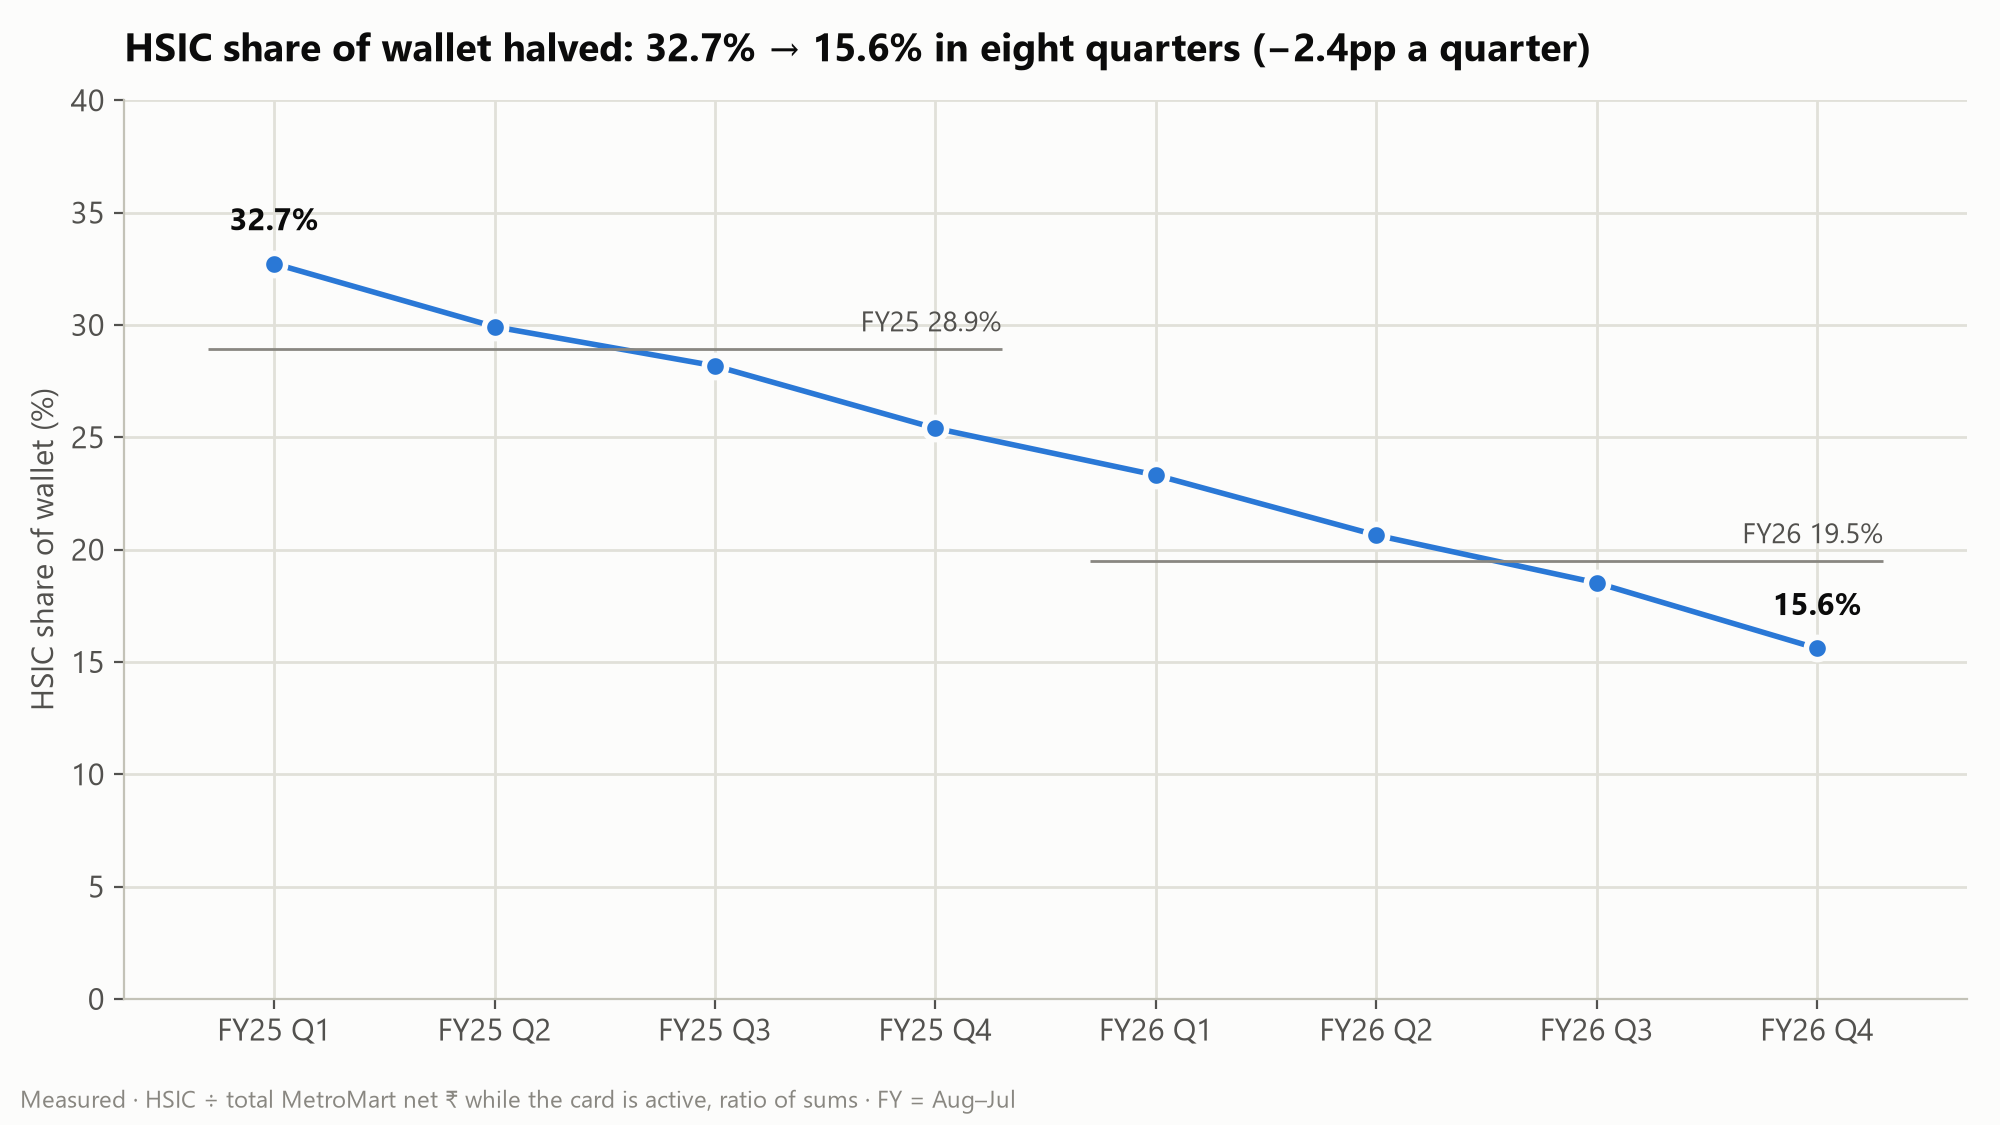

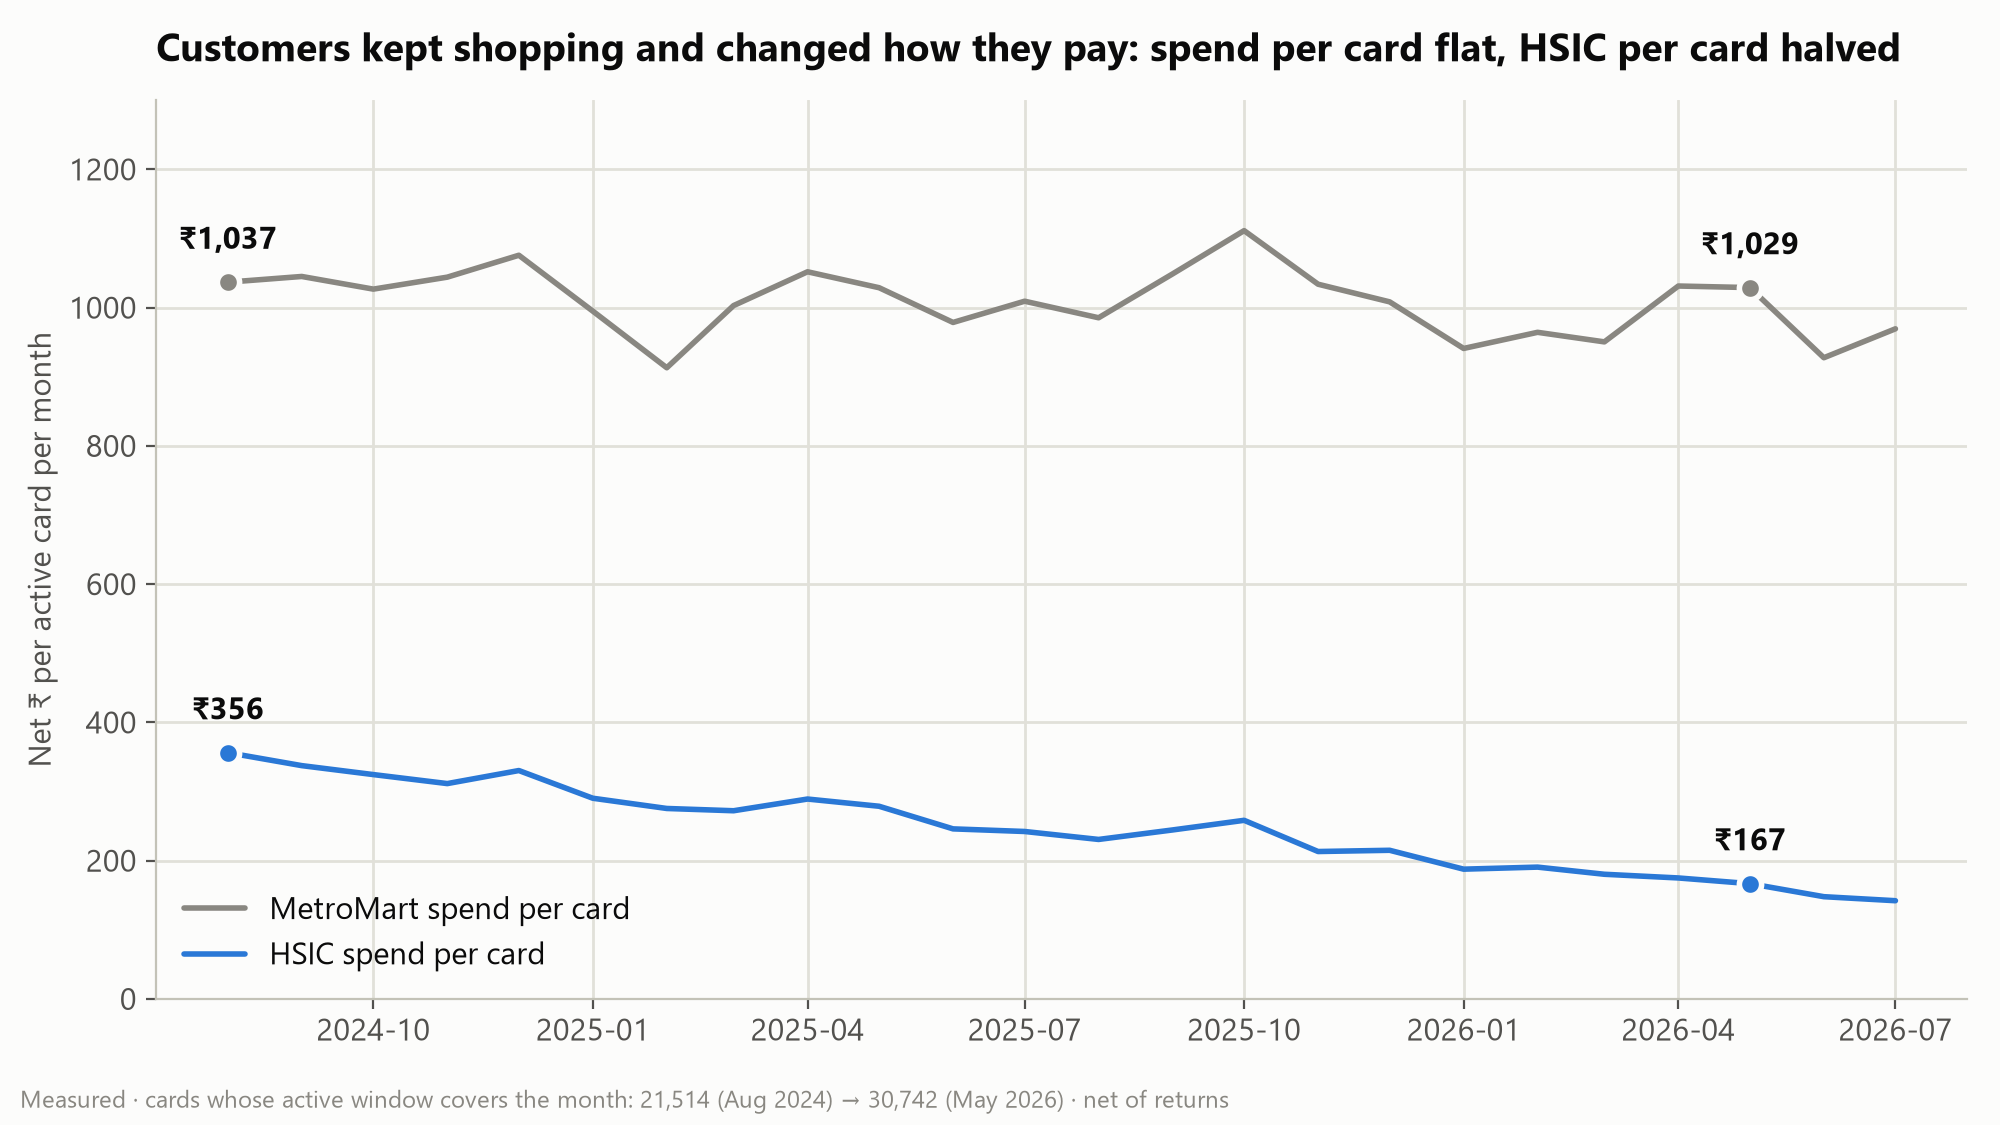

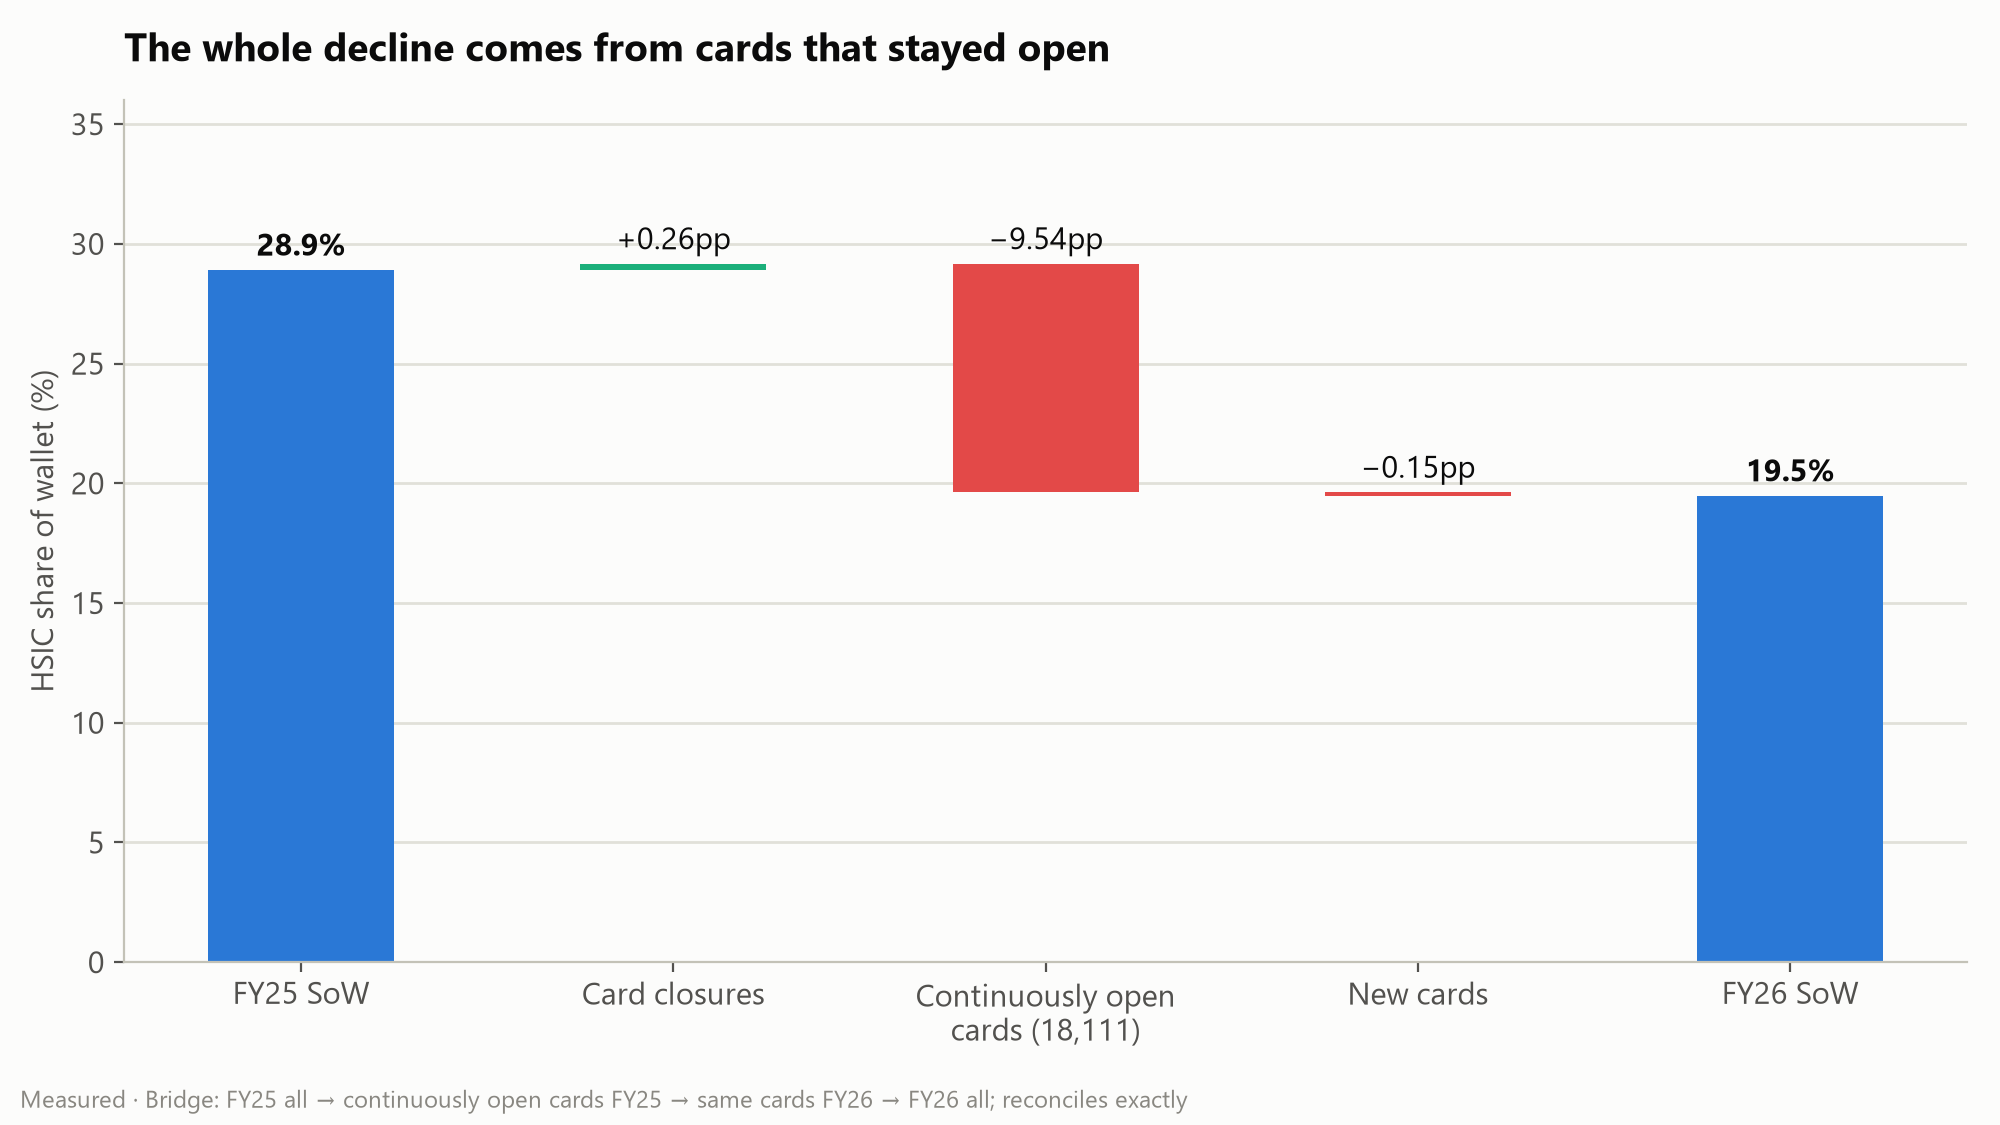

In [4]:
for c in ['04_sow_trend', '04_per_card', '04_bridge']: chart(c)

## Slide 5: where it went
Cash/UPI took almost half of HSIC's lost share, in every ticket band. Why Cash/UPI is a **Hypothesis** (H-imm).

In [5]:
show('f3_cash_upi_share_of_loss', 'f3_debit_share_of_loss', 'f3_other_cc_share_of_loss', 'f3_wallet_share_of_loss',
     'f4_cash_upi_change_pp_stayers', 'f4_cash_upi_change_pp_noncardholders', 'f6_hsic_row_share_t1', 'f6_hsic_row_share_t3',
     'f7_wallet_share_capped_fy26', 'f8_prime_ge_left_on_table')

f3_cash_upi_share_of_loss                   0.467826
f3_debit_share_of_loss                      0.206559
f3_other_cc_share_of_loss                   0.190102
f3_wallet_share_of_loss                     0.135513
f4_cash_upi_change_pp_stayers                4.46523
f4_cash_upi_change_pp_noncardholders        1.843725
f6_hsic_row_share_t1                        0.171003
f6_hsic_row_share_t3                        0.255765
f7_wallet_share_capped_fy26                 0.511394
f8_prime_ge_left_on_table               1603018.6419
dtype: object

In [6]:
F.ticket_band_table().mul(100).round(1)

payment_short     Cash/UPI  Debit  HSIC  Other CC  Wallet
ticket_band fy                                           
<1k         2025      21.8   22.4  23.3      15.0    17.5
            2026      25.3   25.0  15.0      17.5    17.2
1k-3k       2025      20.0   11.8  27.9      10.8    29.5
            2026      24.3   13.9  18.3      12.8    30.7
3k-10k      2025      19.8    9.4  28.8       9.9    32.1
            2026      24.2   11.4  19.3      11.6    33.5
capped      2025      14.5    2.4  30.1       4.5    48.5
            2026      18.9    3.1  21.7       5.2    51.1

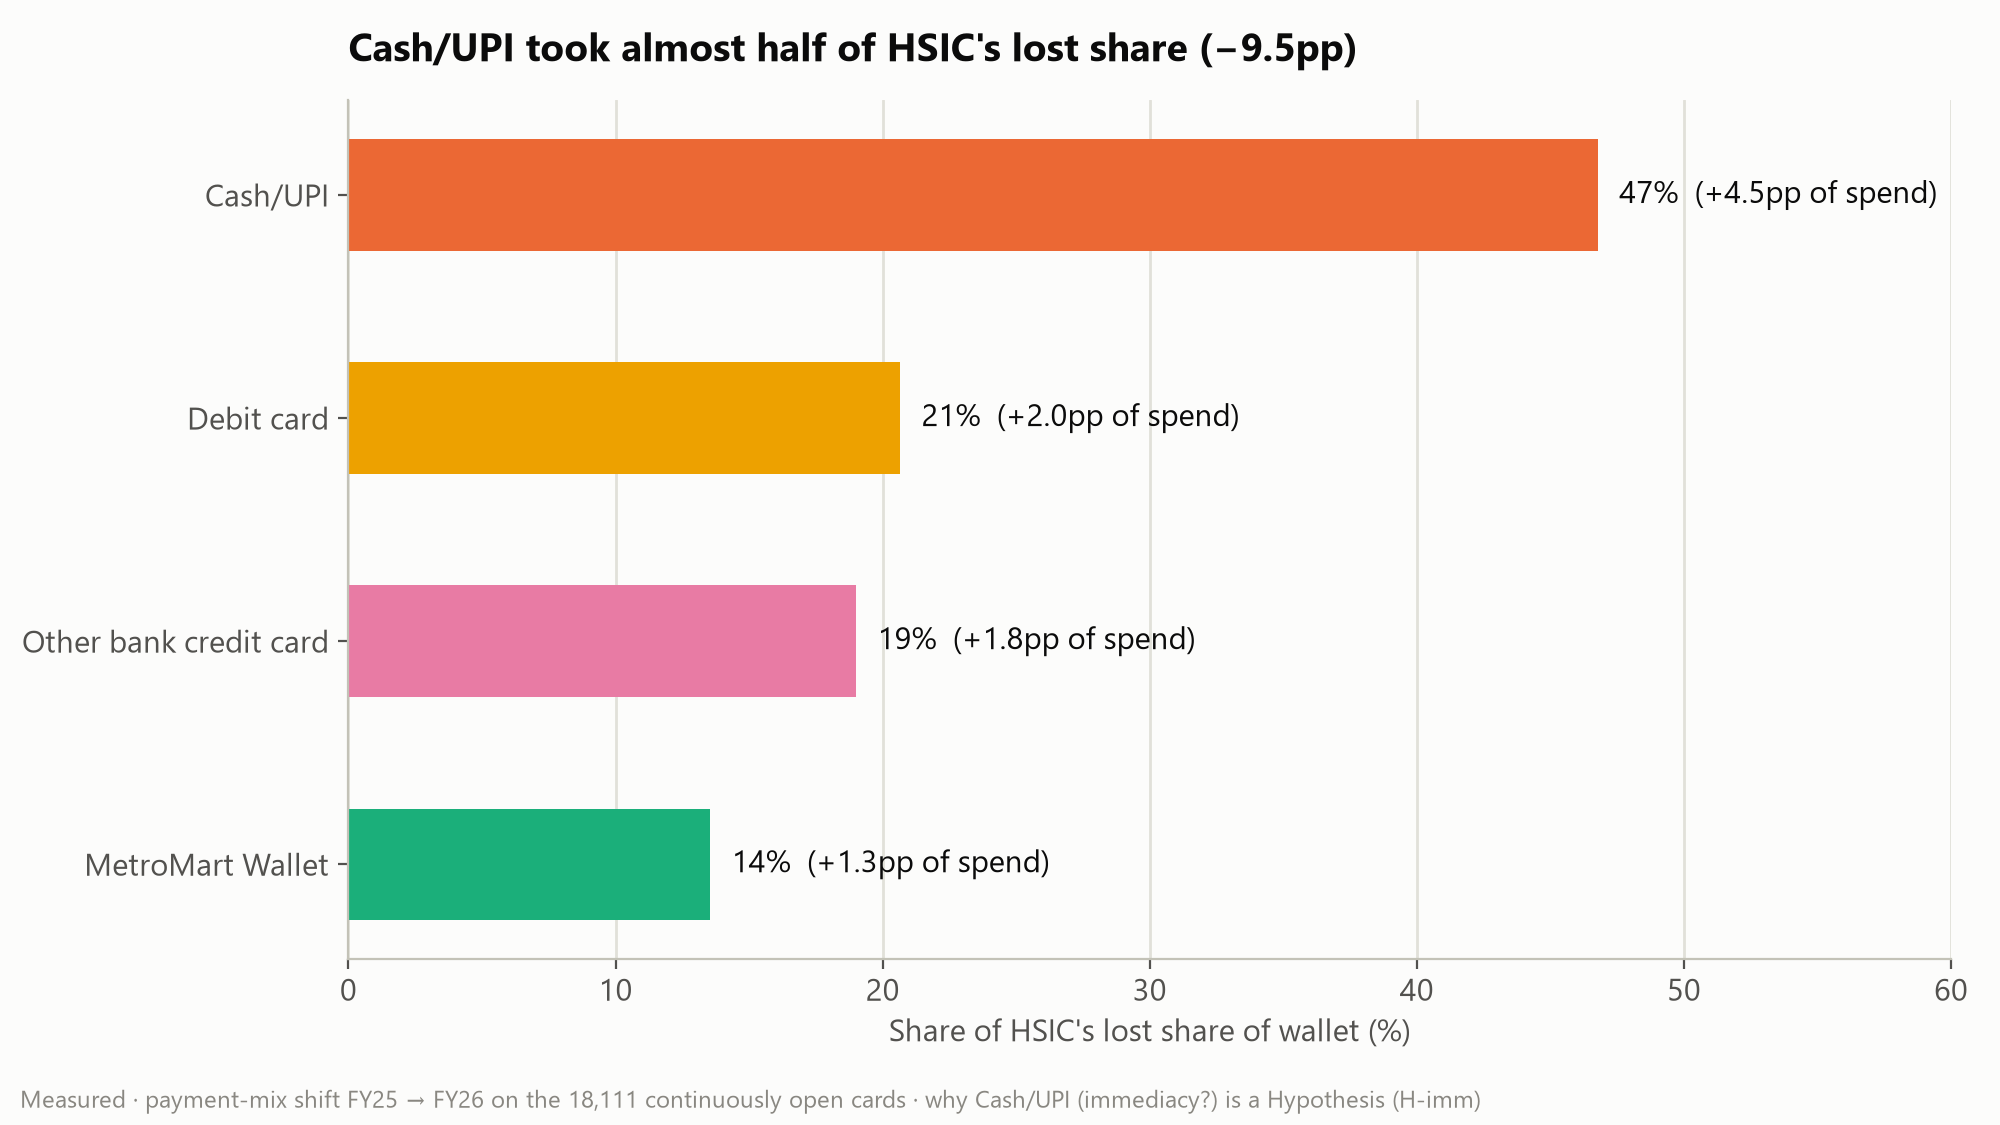

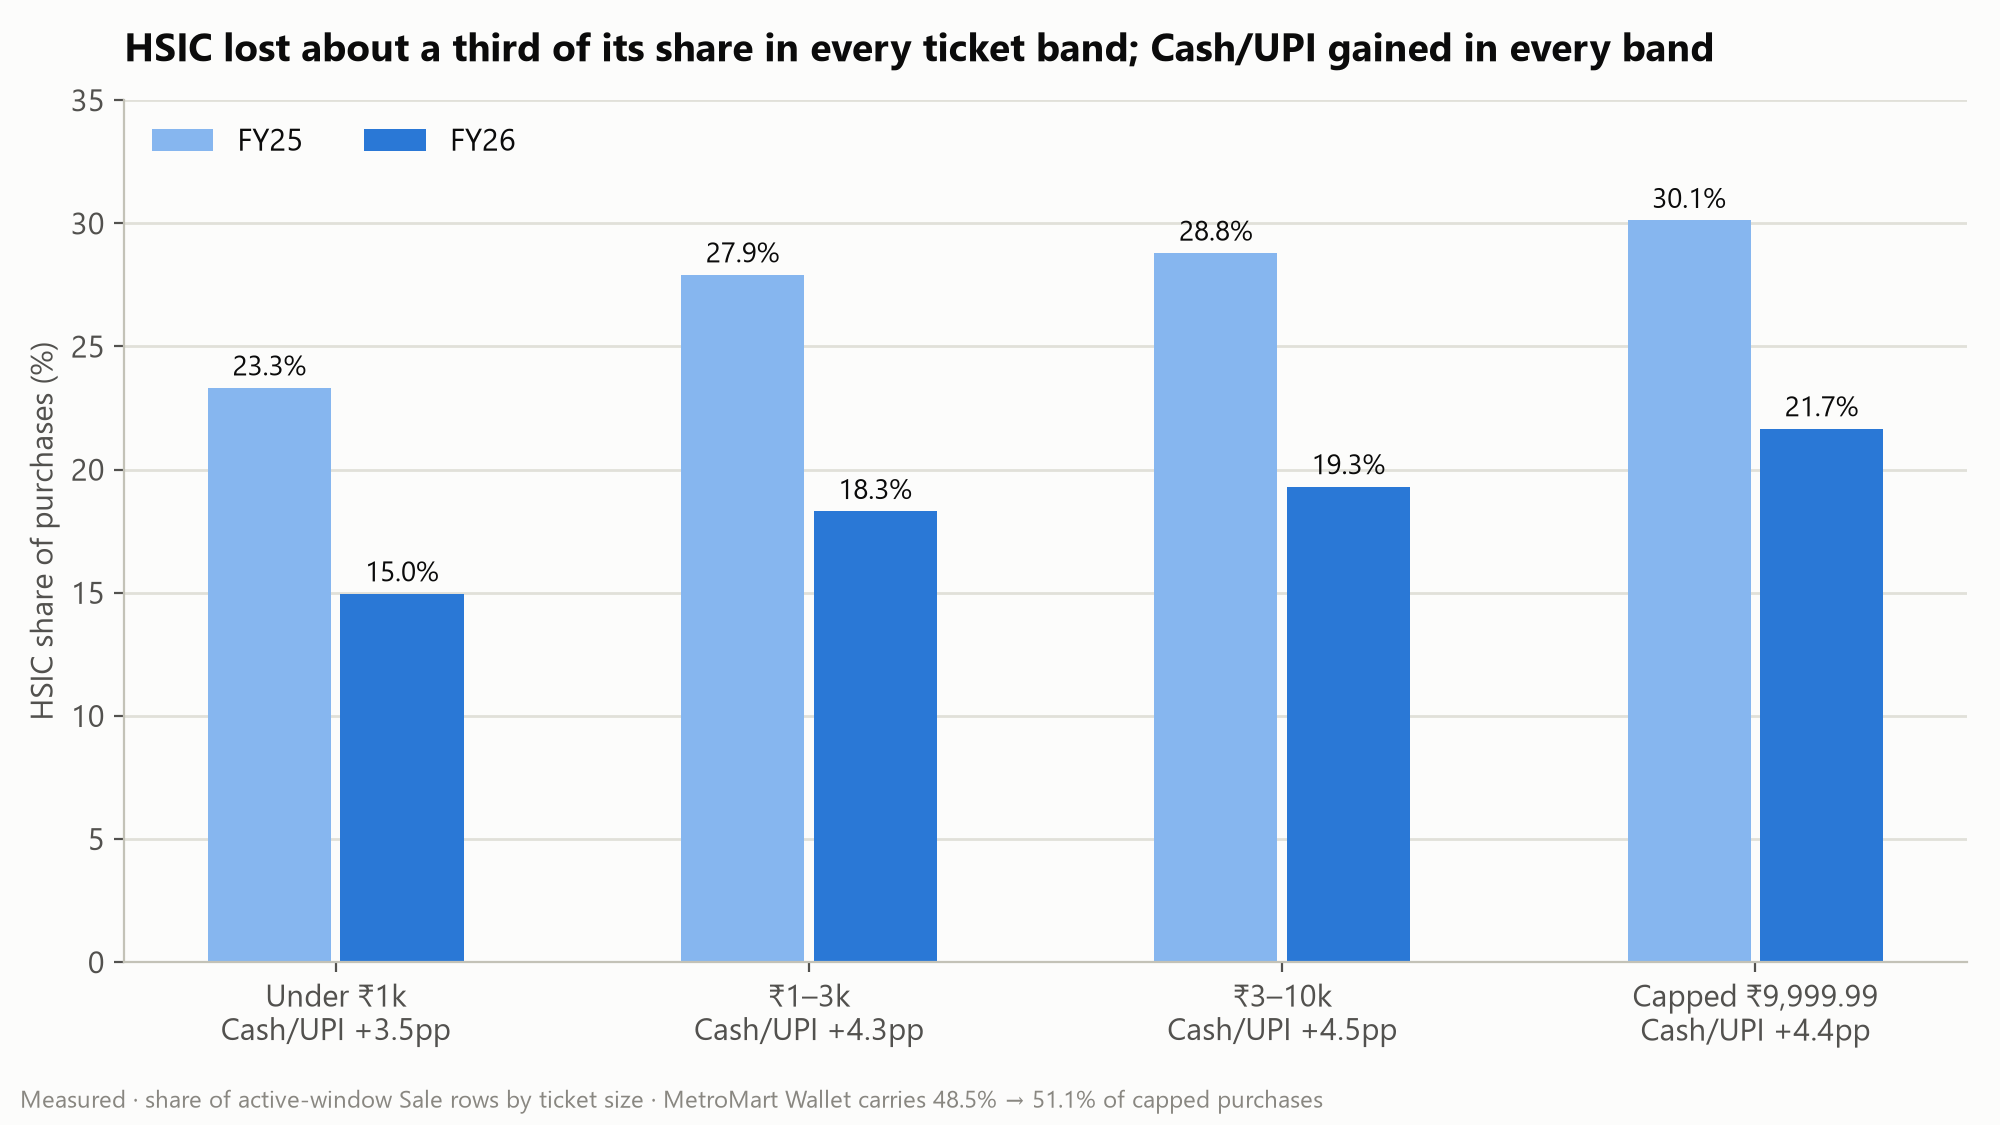

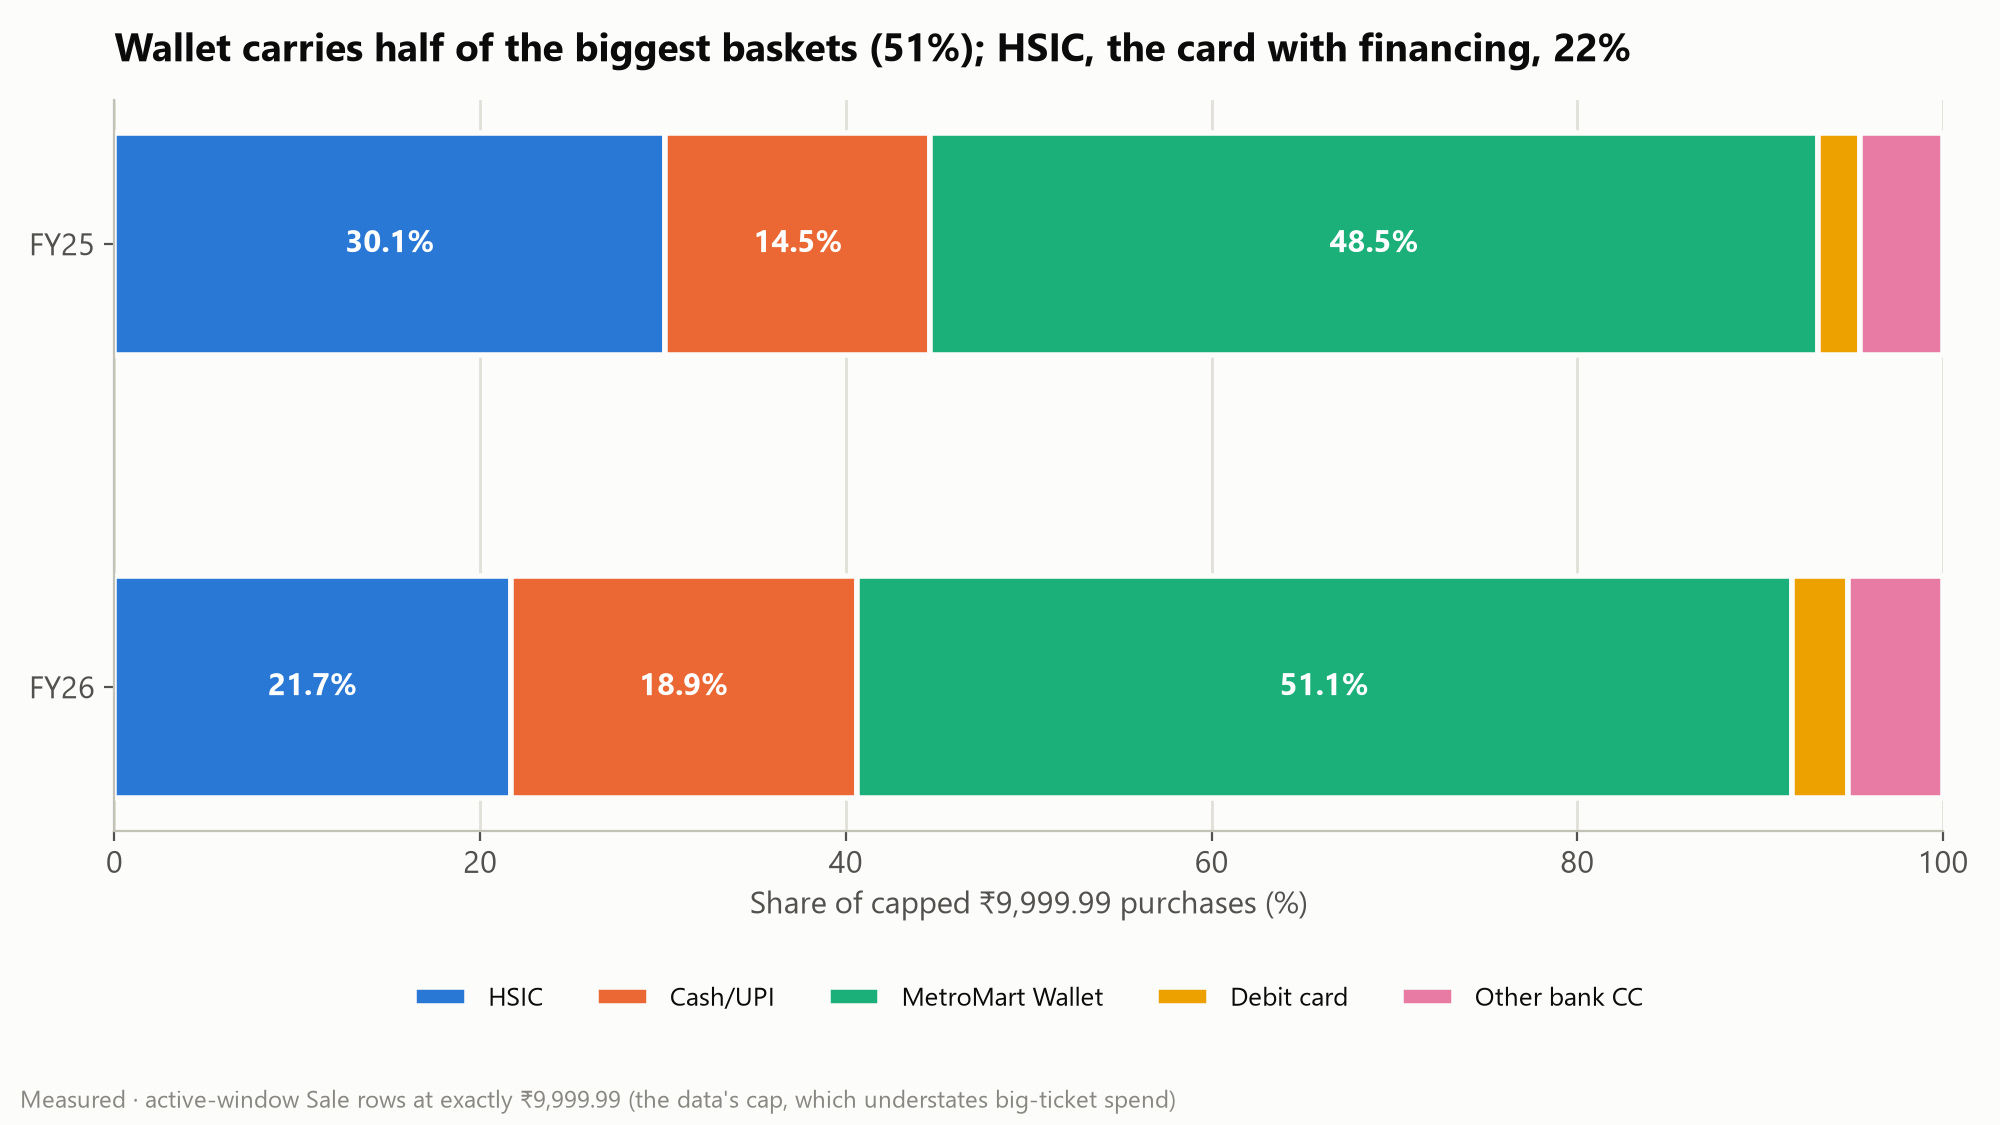

In [7]:
for c in ['05_mix_shift', '05_ticket_bands', '05_capped_mix']: chart(c)

## Slide 6: silent attrition is universal
Every slice fell by about the same amount; the heterogeneity gate (Devansh's X1) shows customers don't differ beyond chance.

In [8]:
H.slice_table().round(3)

,dimension,level,sow_fy25,sow_fy26,change_pp
0,Membership,Non-Prime,0.293,0.191,-10.204
1,Membership,Prime,0.286,0.197,-8.895
2,Age,18-25,0.293,0.199,-9.426
3,Age,26-35,0.290,0.193,-9.733
4,Age,36-45,0.293,0.197,-9.568
5,Age,46-60,0.282,0.192,-8.990
6,Credit limit,Q1 low,0.291,0.197,-9.428
7,Credit limit,Q2,0.286,0.191,-9.484
8,Credit limit,Q3,0.289,0.201,-8.799
9,Credit limit,Q4 high,0.291,0.191,-10.013


In [9]:
show('x8_gap_fy25_pp', 'x8_gap_fy26_pp', 'x8_verdict', 'x9_spread_fy25_pp', 'x9_verdict',
     'x1_variance_ratio_fy25', 'x1_split_half_r', 'x1_persistence_r', 'x1_band_to_zero_min', 'x1_band_to_zero_max')

x8_gap_fy25_pp            0.701795
x8_gap_fy26_pp            0.607727
x8_verdict                rejected
x9_spread_fy25_pp         2.122236
x9_verdict                rejected
x1_variance_ratio_fy25    1.000914
x1_split_half_r          -0.005091
x1_persistence_r          0.003725
x1_band_to_zero_min       0.350694
x1_band_to_zero_max       0.366677
dtype: object

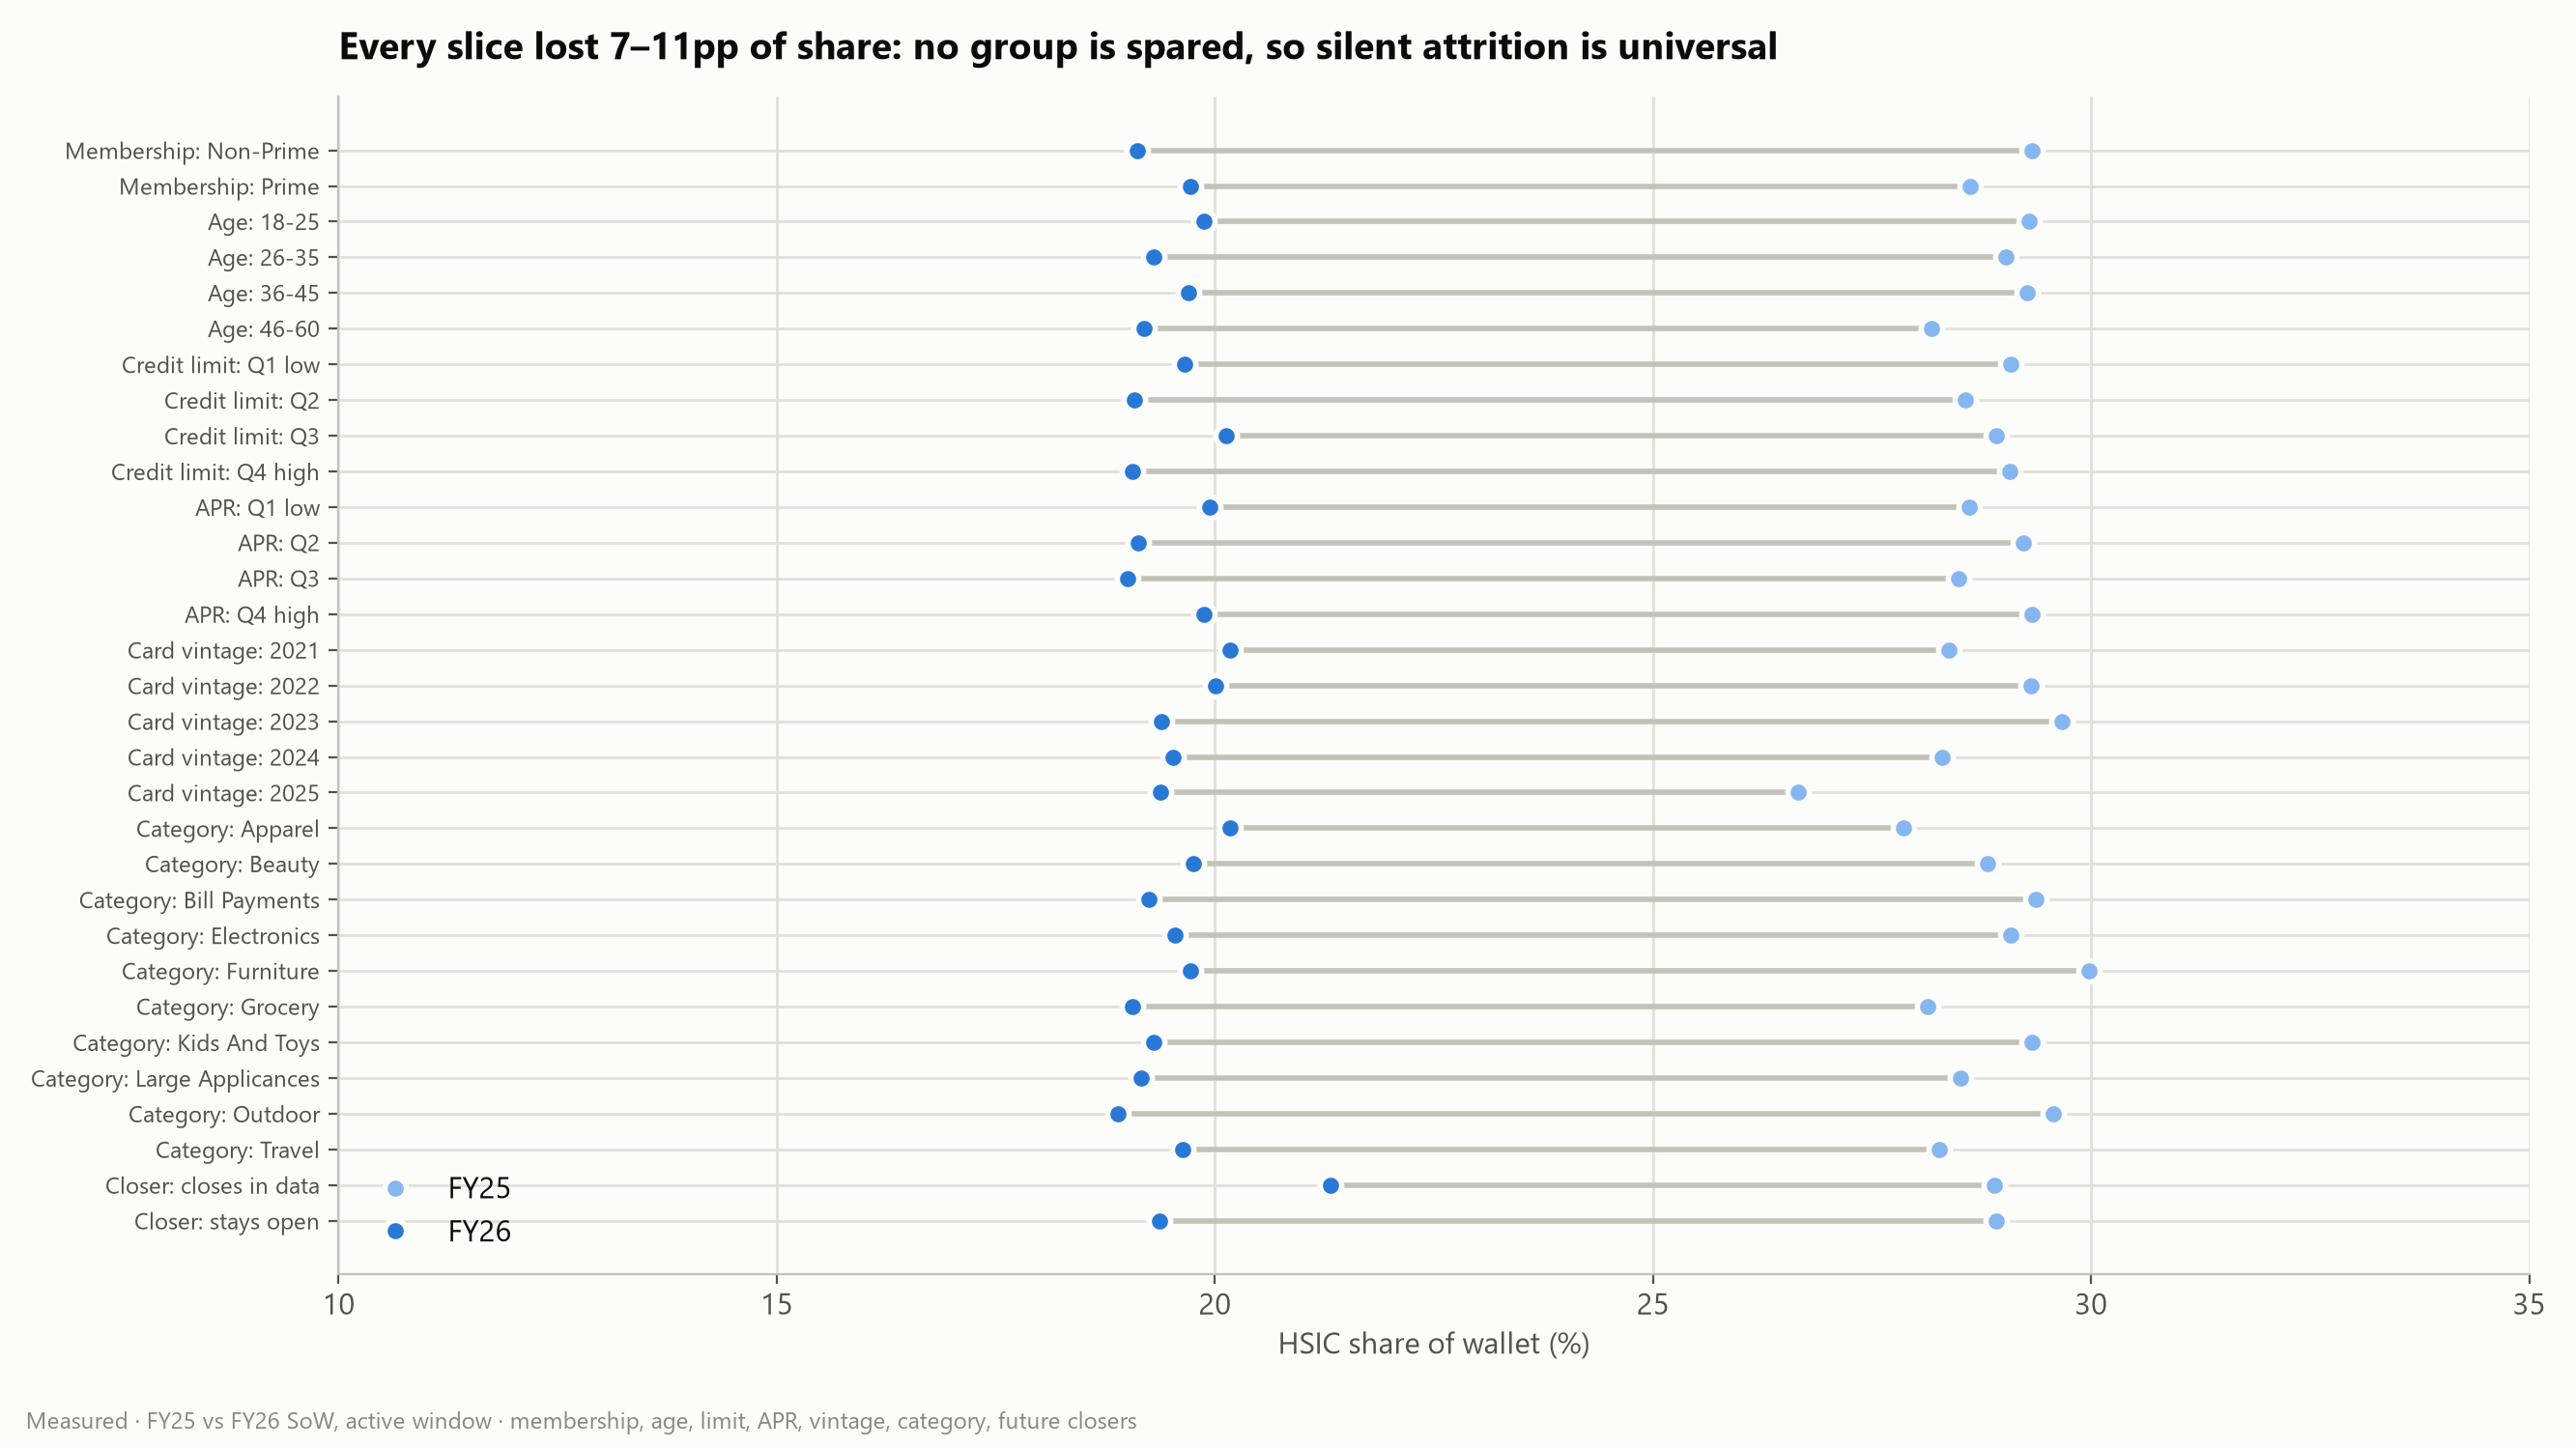

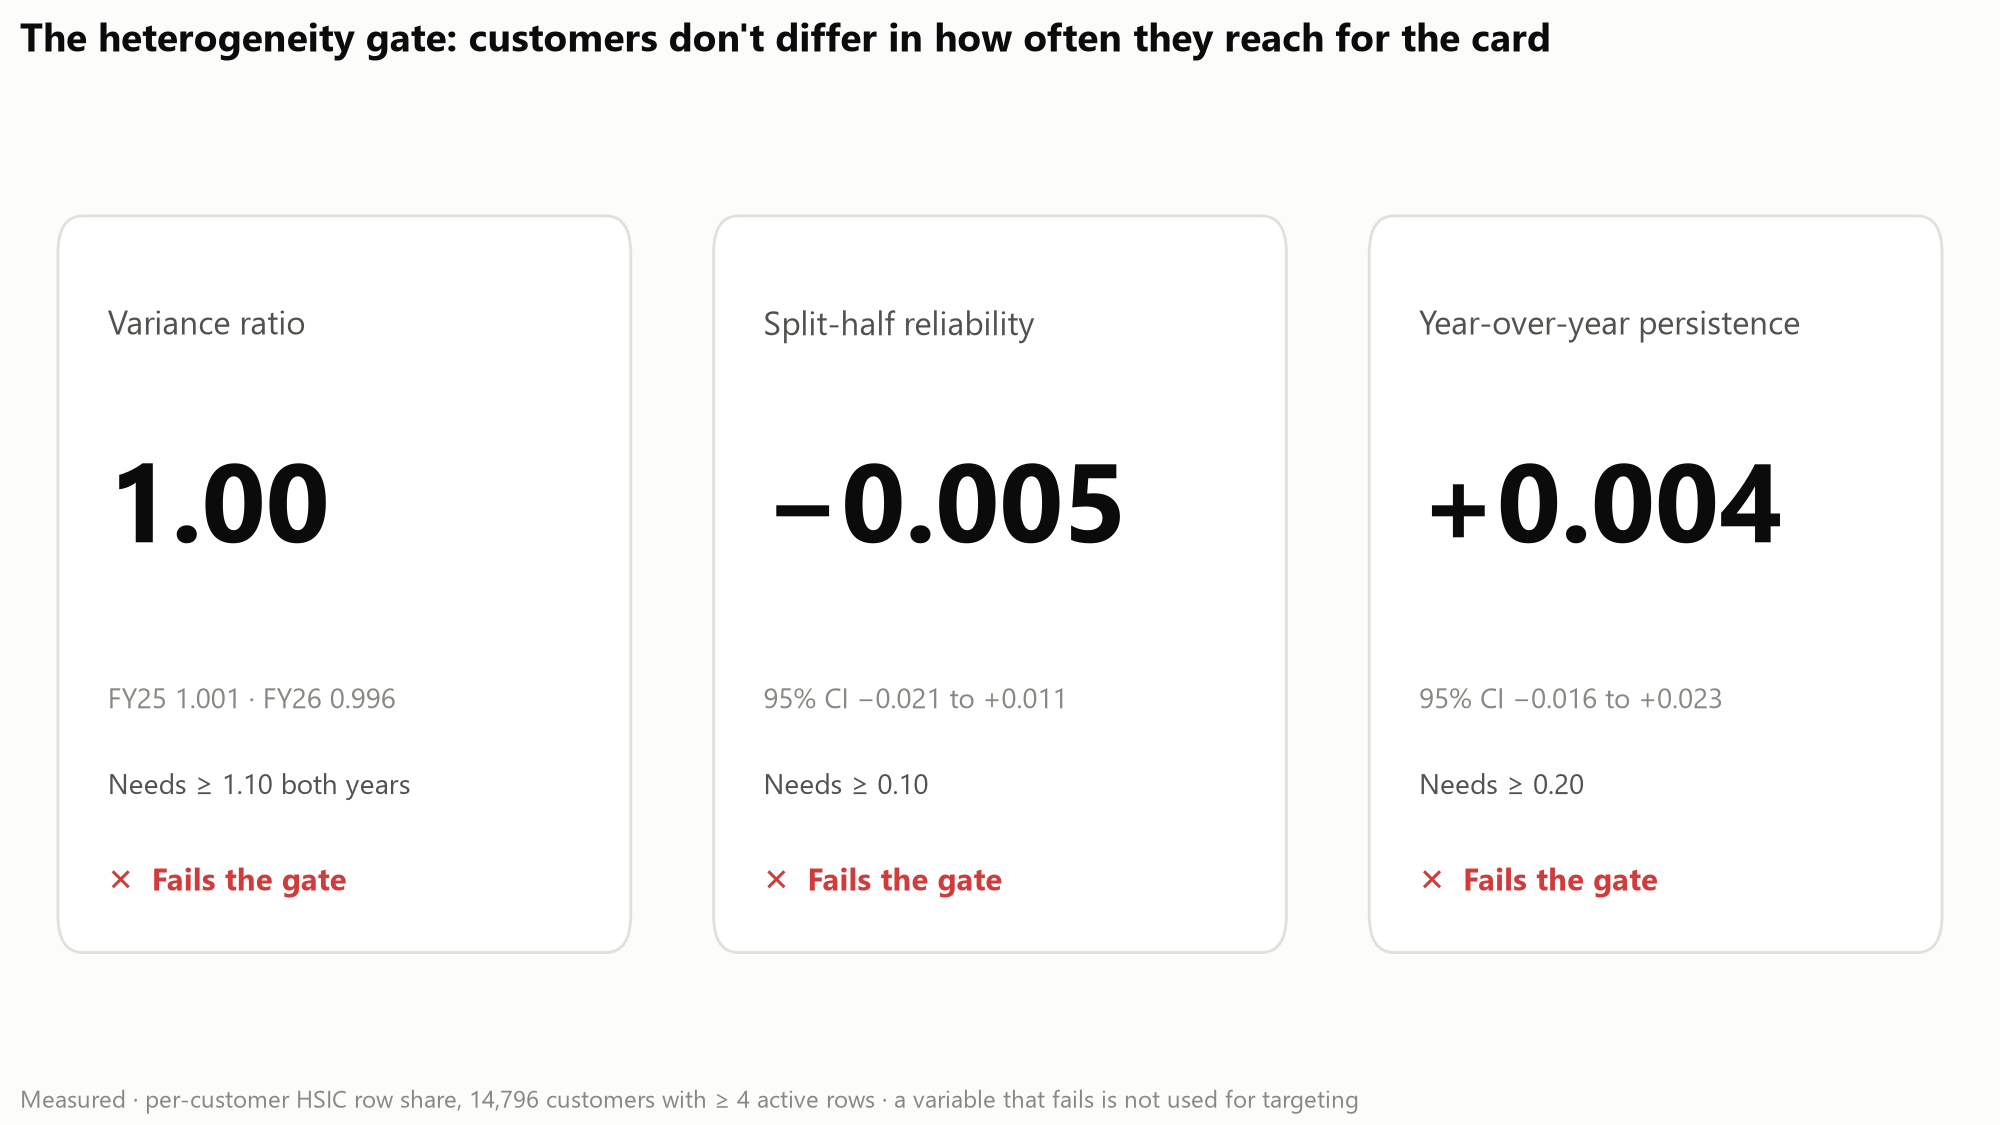

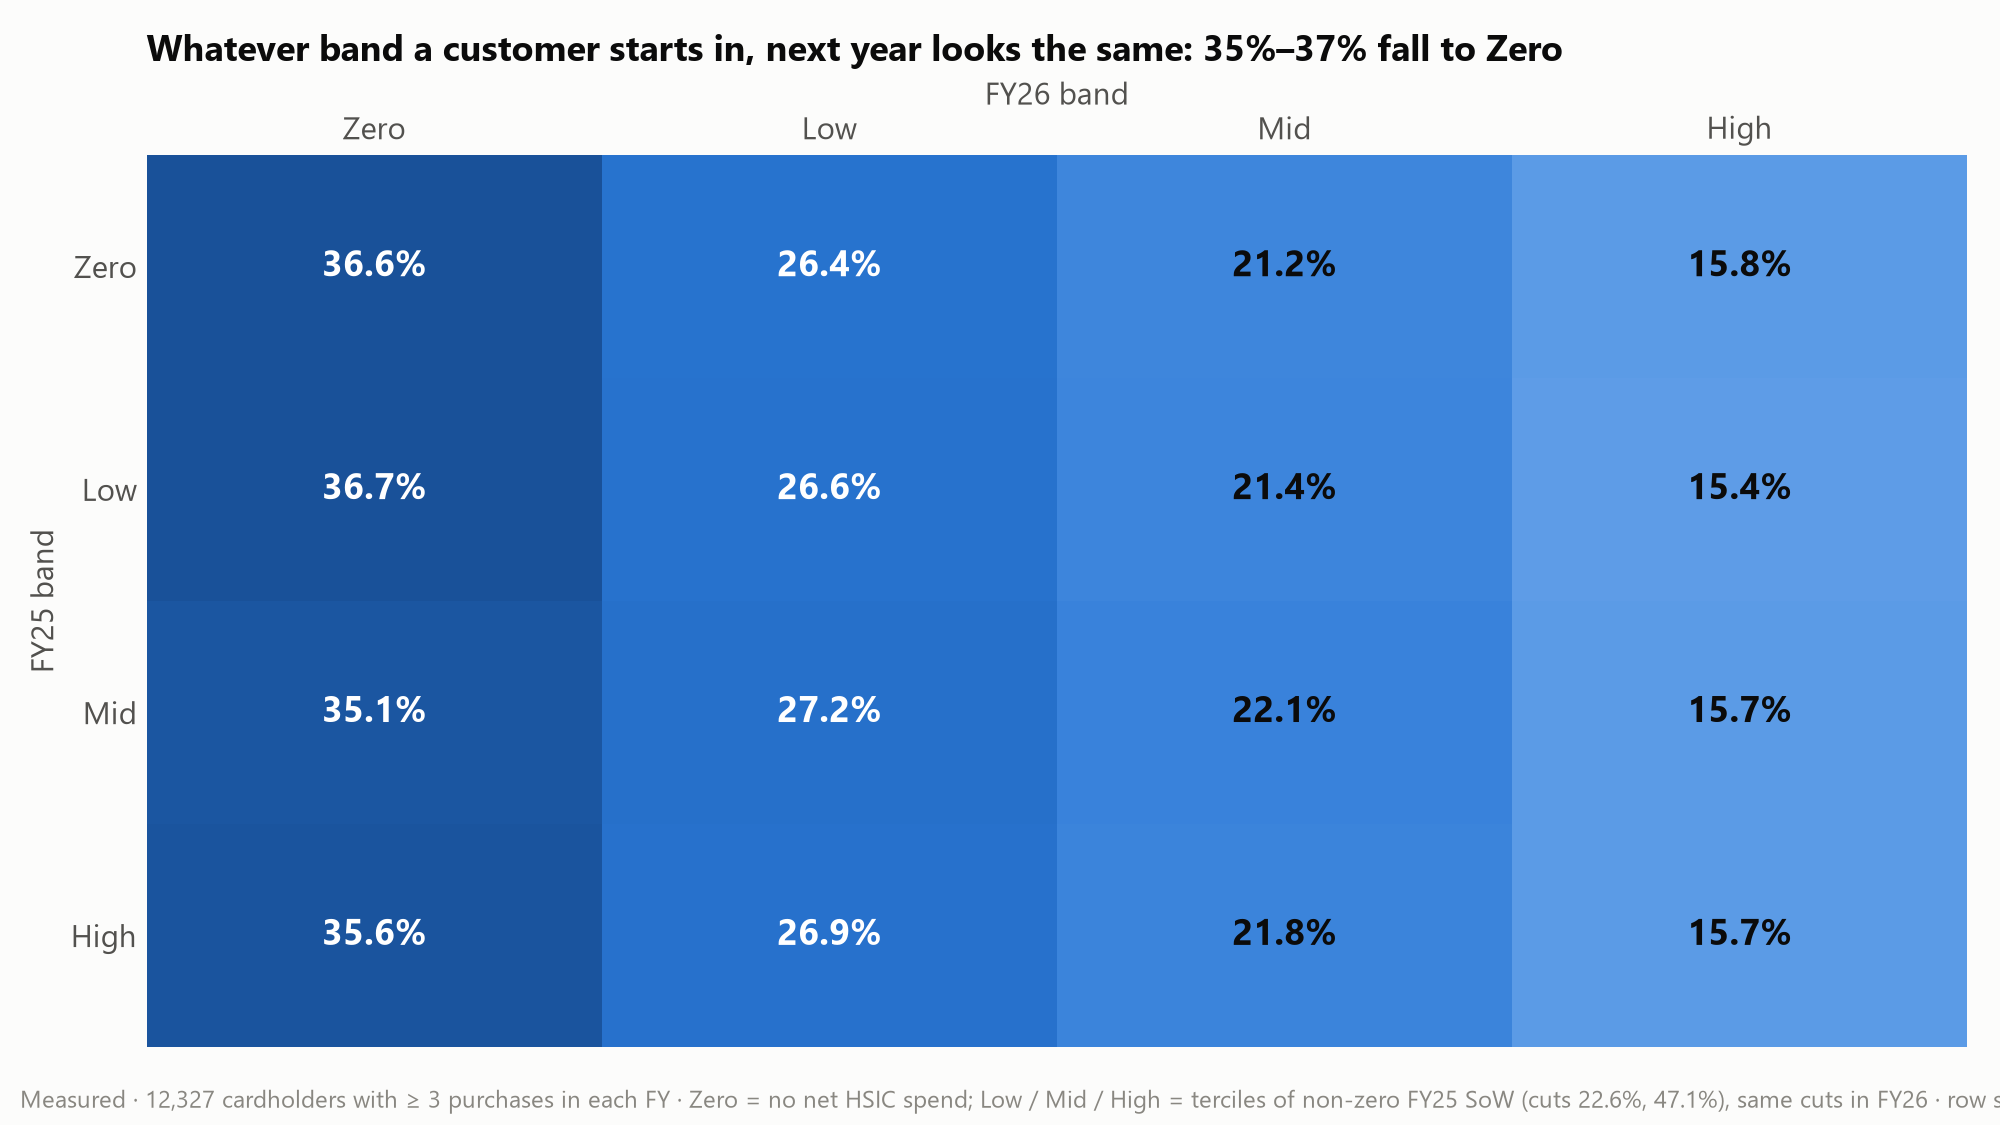

In [10]:
for c in ['06_slices', '06_gate', '06_band_movement']: chart(c)

## Slide 7: common hypotheses we tested
Against the portfolio trend, the ~21pp of "silent attriters" vanish; the pre-closure decay is the calendar; K-means on SoW finds noise.

In [11]:
H.silent_attrition_table().round(4)

C:\Users\asus\AppData\Local\Temp\ipykernel_17000\7977115.py:1: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  H.silent_attrition_table().round(4)


,cutoff,customers,observed,portfolio_share,expected_fixed,expected_time,excess_fixed,excess_fixed_lo,excess_fixed_hi,excess_time,excess_time_lo,excess_time_hi
0,2025-01-31,7297,0.4736,0.2523,0.2579,0.4695,0.2157,0.2041,0.2274,0.0041,-0.0065,0.0147
1,2025-07-31,11897,0.5406,0.2031,0.3655,0.5407,0.1752,0.1661,0.1843,-0.0000,-0.0083,0.0083
2,2026-01-31,12100,0.6232,0.1579,0.4082,0.6259,0.2150,0.2062,0.2239,-0.0027,-0.0108,0.0055


In [12]:
show('x3_verdict', 'x4_slope_pp_per_month', 'x4_slope_ci_lo_pp', 'x4_slope_ci_hi_pp', 'x4_verdict',
     'seg_kmeans_ari', 'seg_kmeans_eta2', 'seg_kmeans_verdict')

x3_verdict                                             universal
x4_slope_pp_per_month                                   0.081431
x4_slope_ci_lo_pp                                      -0.087879
x4_slope_ci_hi_pp                                        0.25074
x4_verdict                    no decay beyond the calendar trend
seg_kmeans_ari                                          0.889101
seg_kmeans_eta2                                         0.000435
seg_kmeans_verdict       clusters do not predict next year's SoW
dtype: object

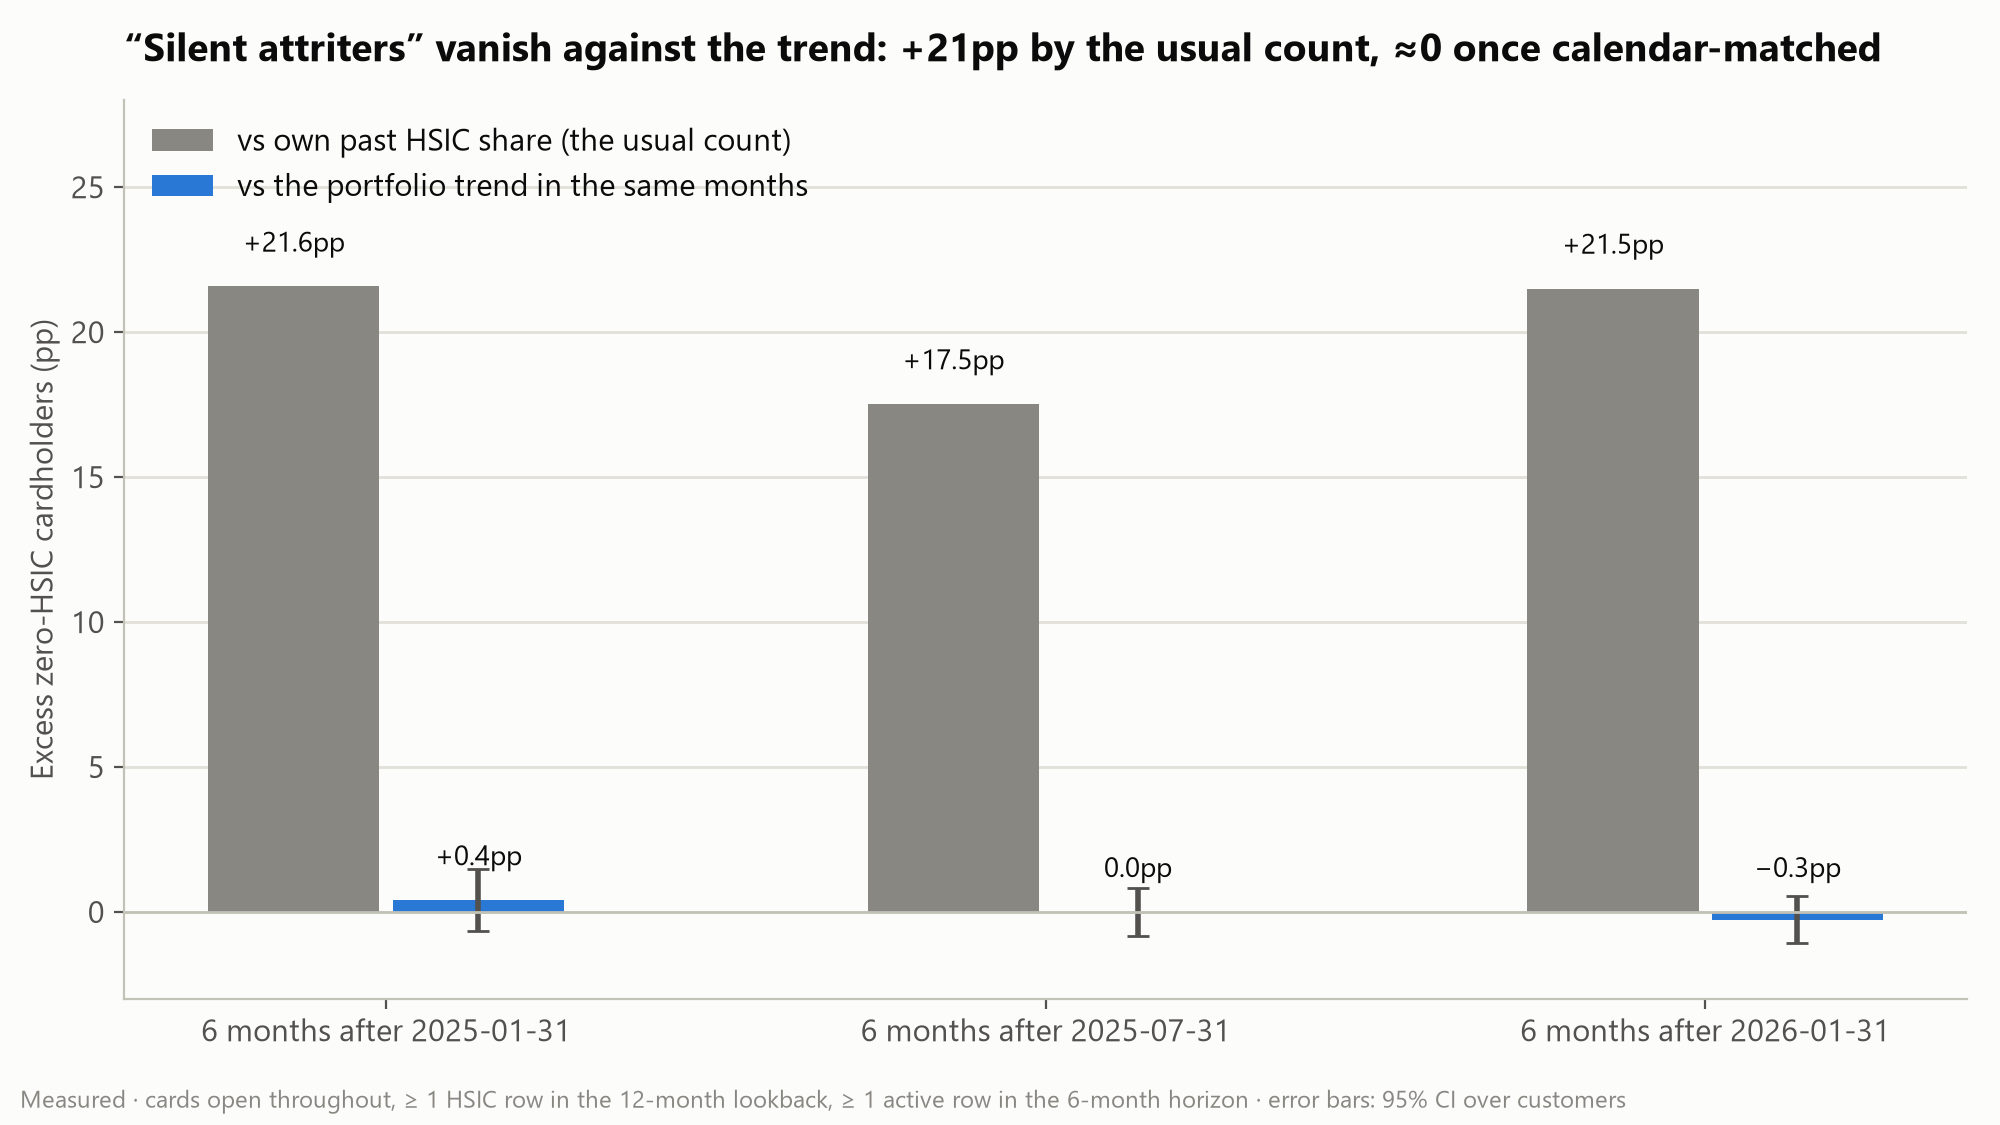

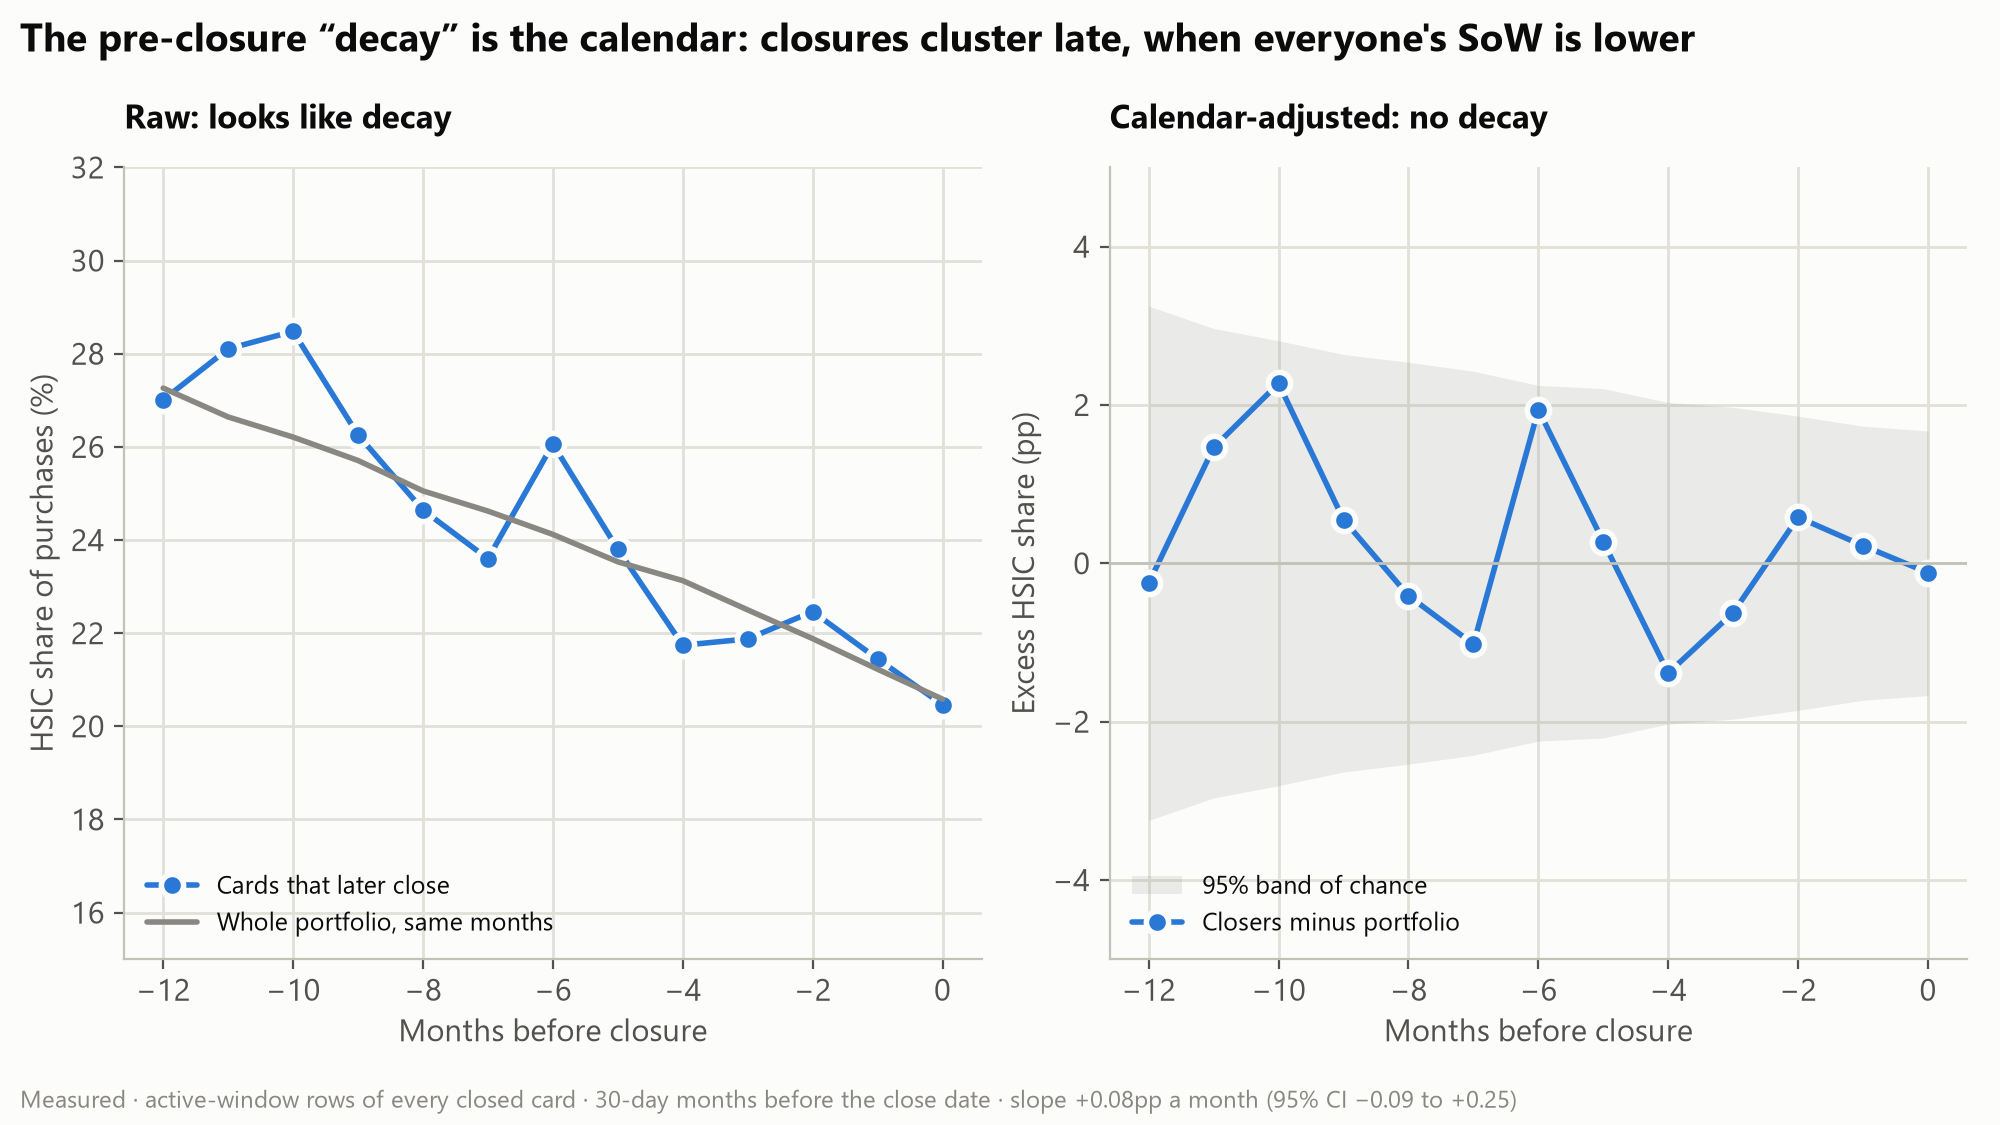

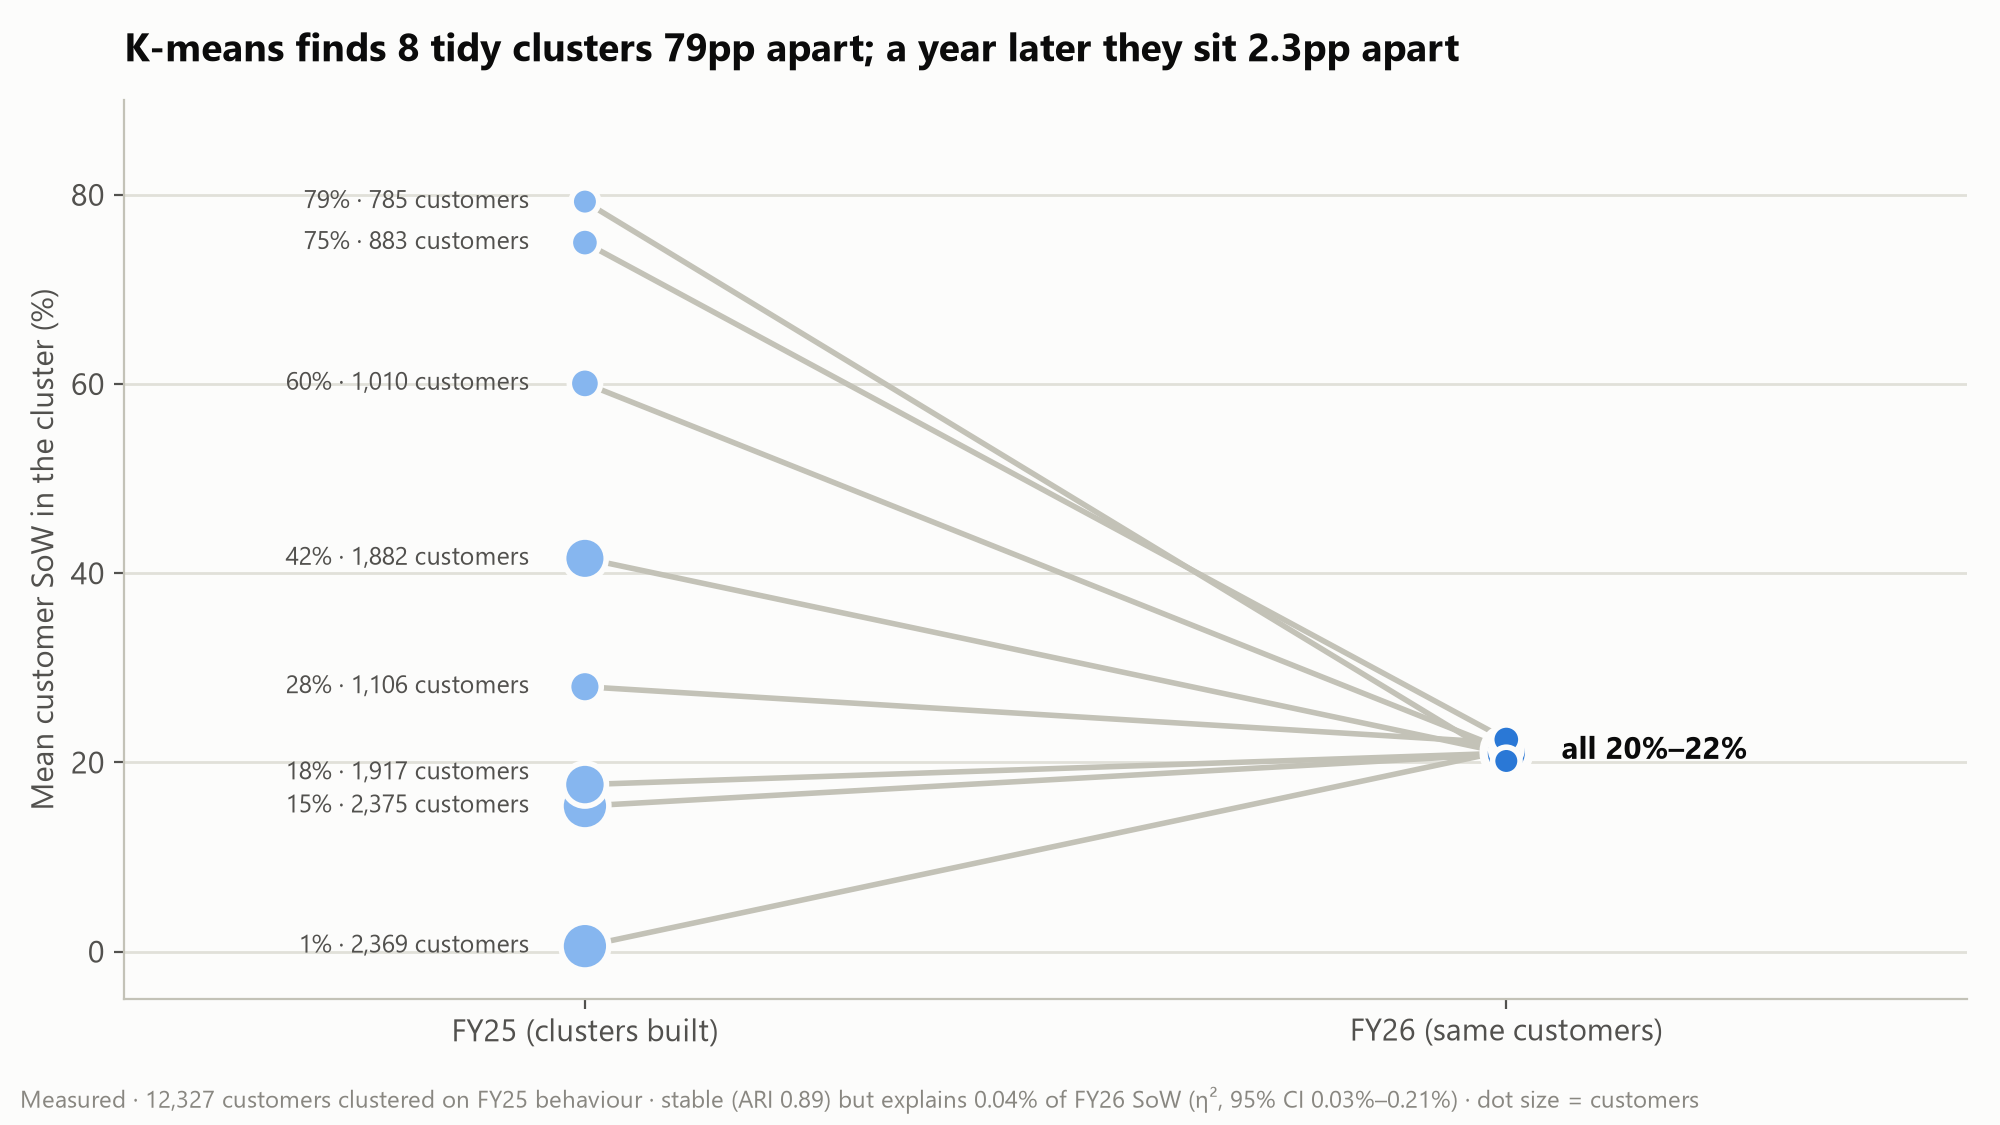

In [13]:
for c in ['07_silent_null', '07_decay_raw_vs_adj', '07_kmeans']: chart(c)

## The other tests (appendix)

In [14]:
pd.read_csv(C.OUTPUTS / 'experiment_log.csv')

,id,expected,verdict,result
0,X1,Clustering customers on SoW reveals low-SoW se...,no customer-level differences beyond chance,x1_variance_ratio_fy25 = 1.001; x1_split_half_...
1,X2,A detector can flag individual customers whose...,nothing to detect,x2_naive_flag_rate_observed = 0.4728; x2_naive...
2,X3,Silent attrition is concentrated in some cardh...,universal,x3_excess_time_2026_01_31 = -0.002665; x3_exce...
3,X4,HSIC use decays before a card closes,no decay beyond the calendar trend,x4_slope_pp_per_month = 0.08143
4,X5,Recent card usage predicts closure,usage adds no closure signal beyond card age,x5_usage_roc_auc = 0.567; x5_usage_increment_r...
5,X6,Gradient boosting beats logistic regression,HGB does not beat LR,x6_hgb_minus_lr = -0.008627; x6_ci_lo = -0.013...
6,X7,New cards show an onboarding usage cliff,no onboarding usage cliff,x7_slope_pp_per_month = -0.03027; x7_max_abs_e...
7,X8,Non-Prime members drop off because 1% is too l...,rejected,NaN
8,X9,Customers keep Grocery on HSIC and move other ...,rejected,NaN
9,X10,Credit limits bind during sale events,rejected,NaN
